In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [ ]:
gray = cv2.imread('sink.jpg',0)

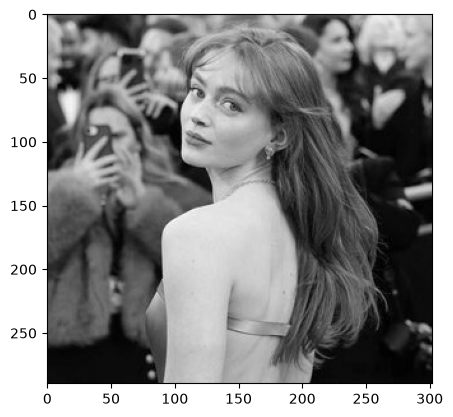

In [10]:
plt.imshow(gray, cmap='gray')

In [11]:
#convolution part
def convolution(image,kernal):
    h,w=image.shape
    result = np.zeros((h,w))
    for i in range(1,h-1):
        for j in range(1,w-1):
            patch = image[i-1:i+2, j-1:j+2]
            result[i,j] = np.sum(patch * kernal)
    return result

In [12]:
#soble kernal
sobel_x = np.array([
    [-1,0,1],
    [-2,0,2],
    [-1,0,1]
])

sobel_y = np.array([
    [-1,-2,-1],
    [0,0,0],
    [1,2,1]
])

#prewitt kernal
prewitt_x = np.array([
    [-1,0,1],
    [-1,0,1],
    [-1,0,1]
])
prewitt_y = np.array([
    [-1,-1,-1],
    [0,0,0],
    [1,1,1]
])

In [18]:
sx = convolution(gray,sobel_x)
sy = convolution(gray,sobel_y)
sx= np.abs(sx)
sy= np.abs(sy)

px = convolution(gray,prewitt_x)
py = convolution(gray,prewitt_y)
px= np.abs(px)
py= np.abs(py)

sobel_magnitude = np.sqrt(sx**2 + sy**2)
prewitt_magnitude = np.sqrt(px**2 + py**2)

sobel = np.uint8(sobel_magnitude / np.max(sobel_magnitude) * 255)
prewitt = np.uint8(prewitt_magnitude / np.max(prewitt_magnitude) * 255)

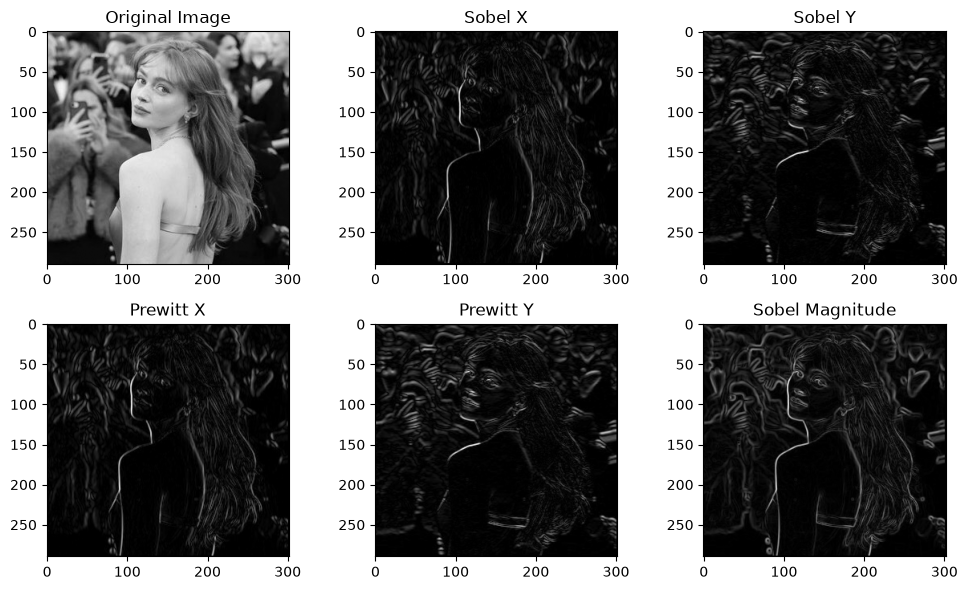

In [19]:
plt.figure(figsize=(10, 6))
plt.subplot(2, 3, 1)
plt.imshow(gray, cmap='gray')
plt.title('Original Image')

plt.subplot(2, 3, 2)
plt.imshow(sx, cmap='gray')
plt.title('Sobel X')

plt.subplot(2, 3, 3)
plt.imshow(sy, cmap='gray')
plt.title('Sobel Y')

plt.subplot(2, 3, 4)
plt.imshow(px, cmap='gray')
plt.title('Prewitt X')

plt.subplot(2, 3, 5)
plt.imshow(py, cmap='gray')
plt.title('Prewitt Y')

plt.subplot(2, 3, 6)
plt.imshow(sobel, cmap='gray')
plt.title('Sobel Magnitude')

plt.tight_layout()
plt.show()